# 

# Imports

In [2]:
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from matplotlib import colors
import matplotlib as mpl
import numpy as np
import re
from seaborn import objects as so


In [21]:

def unflatten(d):
    flat = {}
    for k, v in d.items():
        if type(k) is tuple:
            subkeys = []
            for j in range(len(k)):
                subkey = k[j]
                subdict = flat
                for key in subkeys:
                    subdict = subdict[key]

                if subkey not in subdict:
                    subdict[subkey] = {}

                subkeys.append(subkey)
                if len(k) == len(subkeys):
                    subdict[subkey] = v
        else:
            flat[k] = v

    return flat

def flatten(d, depth=3):
    if depth == 1:
        return d
    flattened = {}
    for k, v in d.items():
        if type(v) is dict:
            flattened_v = flatten(v, depth=depth-1)
            # print(flattened_v)
            for k_2, v_2 in flattened_v.items():
                if type(k_2) is tuple:
                    flattened[tuple([k,] + [_k for _k in k_2])] = v_2
                else:
                    flattened[tuple([k, k_2])] = v_2
        else:
            d[k] = v

    return flattened

original = {(0, 0): 0, (0,1): 1, (0, 2): 2, (1, 0): 3, (1, 0,): 4}

unflattened = unflatten(original)
print(f'Unflattened')
print(unflattened)

flattened = flatten(unflattened, depth=2)
print(f'Flattened')
print(flattened)


Unflattened
{0: {0: 0, 1: 1, 2: 2}, 1: {0: 4}}
Flattened
{(0, 0): 0, (0, 1): 1, (0, 2): 2, (1, 0): 4}


In [3]:
class Constants:
    pandda_2_only = ['A71EV2A-x0365',
                     'A71EV2A-x0310',
                     'A71EV2A-x0515',
                     'A71EV2A-x0450',
                     'A71EV2A-x1247',
                     'A71EV2A-x0416',
                     'A71EV2A-x0836',
                     'A71EV2A-x0451',
                     'A71EV2A-x0884',
                     'A71EV2A-x0732',
                     'A71EV2A-x0566',
                     'A71EV2A-x0719',
                     'A71EV2A-x0351',
                     'A71EV2A-x0875',
                    'A71EV2A-x0554',
                    'A71EV2A-x0812',

                    ]
    pandda_1_cannot_process=[
        'A71EV2A-x0487', 
        'A71EV2A-x0237', 
        'A71EV2A-x1209', 
        'A71EV2A-x0207', 
        'A71EV2A-x1180', 
        'A71EV2A-x1169', 
        'A71EV2A-x0926', 
        'A71EV2A-x1255', 
        'A71EV2A-x1293', 
        'A71EV2A-x0514', 
        'A71EV2A-x1292', 
        'A71EV2A-x0501', 
        'A71EV2A-x0437', 
        'A71EV2A-x0387', 
        'A71EV2A-x0443',
    ]
    pandda_1_confirmed = [
        'A71EV2A-x0278',
        'A71EV2A-x0428',
        'A71EV2A-x0229',
        'A71EV2A-x0556',
        'A71EV2A-x0526',
        'A71EV2A-x0525',
        'A71EV2A-x0517',
        'A71EV2A-x0432',
        'A71EV2A-x0396',
        'A71EV2A-x1081',
    ]
    shortcode_regex=r'([a-zA-Z0-9]+)(?:\s|$)'
    

# Funcctions

In [4]:
def longname_to_dtag(longname):
    match = re.match(r'([\-a-zA-Z0-9]+)_([a-zA-Z0-9]+)_([a-zA-Z0-9]+)_([a-zA-Z0-9]+)', longname)
    return match[1]
def longcode_to_shortcode(code):
    match = re.findall(Constants.shortcode_regex, code)
    # print(len(match))
    # print(match)

    if len(match) > 1:
        return match[0] + '...'
    if len(match) == 0:
        print(code)
        print(match)
    return match[0]

# Setup tables

In [5]:
interactions = pd.read_csv('/Users/jfi22496/Documents/code/pandda_2_paper_figures/data/2A_fragment_interactions.csv')
dtag = interactions['pose_longname'].apply(longname_to_dtag)
interactions['dtag'] = interactions['pose_longname'].apply(longname_to_dtag)
interactions['atom_shortcode'] = interactions['prot_atoms'].apply(longcode_to_shortcode)
interactions = interactions[interactions['type'] != 'Hydrophobic']
sorted_interactions = interactions.set_index(['type', 'chain_name', 'residue_number', 'prot_atoms',  ]).sort_index().loc[:, ['dtag', 'atom_shortcode']]
pandda_2_only_interactions = sorted_interactions[sorted_interactions['dtag'].isin(Constants.pandda_2_only)]
pandda_1_interactions = sorted_interactions[sorted_interactions['dtag'].isin(Constants.pandda_1_confirmed)]


In [6]:
# interactions[interactions['dtag'].isin(Constants.pandda_2_only)]

In [7]:
len(pandda_1_interactions.loc['π-stacking'])

5

# Get interactions dict

In [8]:
interactions_map = {}
interaction_type_index = {
    'Hydrogen Bond': 0,
    'π-stacking': 1,
    'Electrostatic': 2,
    'π-cation': 3,
}
status_map = {
    True: 2,
    False: 1
}
# pr
for interaction_type in sorted_interactions.index.levels[0]:
    for protein_atoms in sorted_interactions.loc[interaction_type].index:
        key = (interaction_type, protein_atoms[0], protein_atoms[1], protein_atoms[2])
        # pandda_status = (key in pandda_2_only_interactions.index) & (key not in pandda_1_interactions.index)
        pandda_status = key not in pandda_1_interactions.index
        interactions_map[(interaction_type, protein_atoms)] = (pandda_status, sorted_interactions.loc[key,'atom_shortcode'])
        

# 

# Plot barcode

In [9]:
dtype = [('chain', '<U4'), ('res_num', '<i4'), ('atoms', '<U150'),  ]
array = np.zeros(
    (
        len(np.unique([x[0] for x in interactions_map])),
        len(np.unique(np.array([x[1] for x in interactions_map], dtype=dtype))),

    )
)
unique_residues = {(key[0], key[1], key[2]): j for j, key in enumerate(np.unique(np.array([x[1] for x in interactions_map], dtype=dtype)))}
print(unique_residues)
for (interaction_type, atom_id), (pandda_status, shortcode) in interactions_map.items():
    array[
        interaction_type_index[interaction_type],
        unique_residues[(atom_id[0], atom_id[1], atom_id[2],) ]
    ] = status_map[pandda_status]

{(np.str_('A'), np.int32(7), np.str_('O')): 0, (np.str_('A'), np.int32(20), np.str_('NH1')): 1, (np.str_('A'), np.int32(21), np.str_('NE2')): 2, (np.str_('A'), np.int32(23), np.str_('O')): 3, (np.str_('A'), np.int32(25), np.str_('CD2 CE1 CG ND1 NE2')): 4, (np.str_('A'), np.int32(25), np.str_('ND1')): 5, (np.str_('A'), np.int32(26), np.str_('ND2')): 6, (np.str_('A'), np.int32(26), np.str_('OD1')): 7, (np.str_('A'), np.int32(28), np.str_('CD1 CD2 CE2 CG NE1')): 8, (np.str_('A'), np.int32(31), np.str_('O')): 9, (np.str_('A'), np.int32(33), np.str_('CD1 CD2 CE2 CG NE1')): 10, (np.str_('A'), np.int32(34), np.str_('OE1 OE2')): 11, (np.str_('A'), np.int32(36), np.str_('N')): 12, (np.str_('A'), np.int32(44), np.str_('O')): 13, (np.str_('A'), np.int32(59), np.str_('N')): 14, (np.str_('A'), np.int32(64), np.str_('CD1 CD2 CE1 CE2 CG CZ')): 15, (np.str_('A'), np.int32(64), np.str_('OH')): 16, (np.str_('A'), np.int32(68), np.str_('O')): 17, (np.str_('A'), np.int32(69), np.str_('NE')): 18, (np.str_(

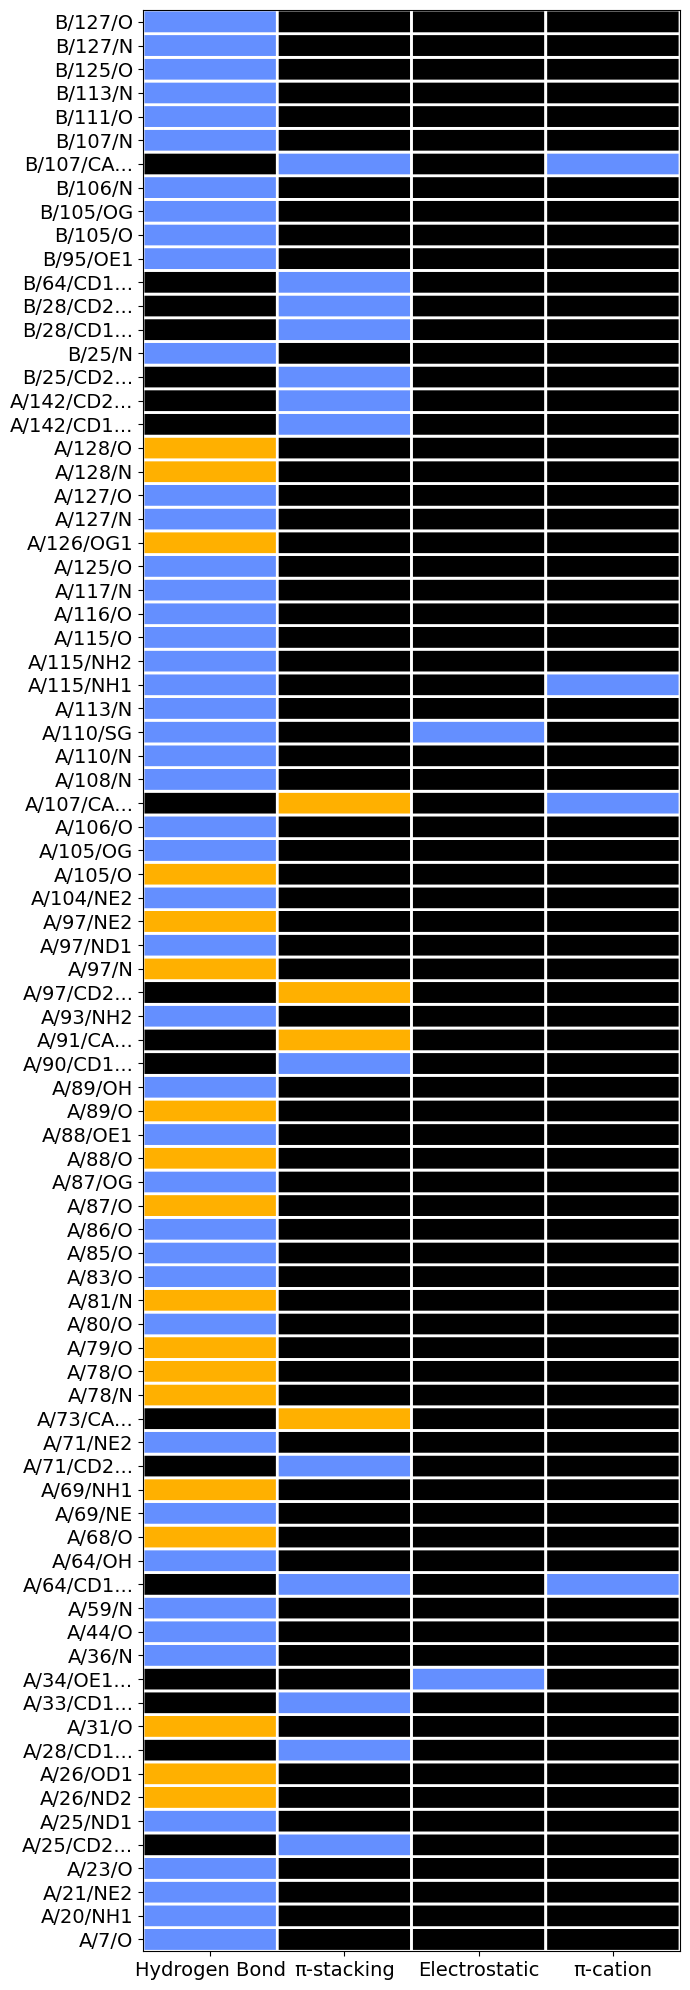

In [10]:
cmap = colors.ListedColormap(['black', '#FFB000', '#648FFF'])
bounds=[0,0.9,1.9,2.9]
norm = colors.BoundaryNorm(bounds, cmap.N)

fig, ax0 = plt.subplots(1, 1, figsize=(7, 20))
# mpl.rc('xtick', labelsize=8) 
# mpl.rc('ytick', labelsize=1) 
arrayc = ax0.pcolor(array.T, cmap=cmap, norm=norm, edgecolors='w', linewidths=2)
ax0.set_xticks(
    [x + 0.5 for x in interaction_type_index.values()], 
)
ax0.set_xticklabels(
    [x for x in interaction_type_index.keys()]
)
ax0.set_yticks(
    [x +0.5 for x in unique_residues.values()], 
)
ax0.set_yticklabels(
    ["/".join([longcode_to_shortcode(str(y)) for y in x]) for x in unique_residues.keys()],
    # rotation=45,
    horizontalalignment='right'
)
ax0.tick_params(axis='both', which='major', labelsize=14)

plt.tight_layout()
#plt.savefig('/dls/data2temp01/labxchem/data/2017/lb18145-17/processing/paper_images/FigInteractionMap')

# Plot stacked bars

In [13]:

records = []
for _interaction_type in interaction_type_index:
    # try:
    #     pandda_1_only_interaction_num = len(pandda_1_interactions.loc[_interaction_type])
    # except Exception:
    #     pandda_1_only_interaction_num = 0
    # try:
    #     pandda_2_interaction_num = pandda_1_only_interaction_num + len(pandda_2_only_interactions.loc[_interaction_type])
    # except Exception:
    #     pandda_2_interaction_num = 0

    pandda_2_interaction_num = len(interactions[(interactions['type'] == _interaction_type) & (~interactions['dtag'].isin(Constants.pandda_1_cannot_process))]['resid'].unique())
    pandda_1_only_interaction_num = len(interactions[(interactions['type'] == _interaction_type) & (interactions['dtag'].isin(Constants.pandda_1_confirmed)) & (~interactions['dtag'].isin(Constants.pandda_1_cannot_process))]['resid'].unique())
    
    records.append(
        {
            'Interaction Type': _interaction_type,
            'Unique Interactions': pandda_2_interaction_num,
            'PanDDA Version': 'PanDDA 2'
        }
    )
    records.append(
        {
            'Interaction Type': _interaction_type,
            'Unique Interactions': pandda_1_only_interaction_num,
            'PanDDA Version': 'PanDDA'
        }
    )

plot_df = pd.DataFrame(records)

In [14]:
interactions[(interactions['type'] == 'π-stacking') & (interactions['dtag'].isin(Constants.pandda_1_confirmed))]

,pose_longname,id,feature_id,pose_id,target_id,type,prot_family,lig_family,residue_name,residue_number,...,prot_coord,lig_coord,prot_atoms,lig_atoms,backbone,sidechain,pose_name,dtag,atom_shortcode,resid
2,A71EV2A-x0278_A_147_v1,3,737,1,1,π-stacking,Aromatic,Aromatic,HIS,97,...,"[11.0488, 12.932400000000001, 5.443]","[8.756166666666667, 14.053333333333333, 2.5665]",CD2 CE1 CG ND1 NE2,"[7, 8, 9, 10, 11, 12]",False,True,A0278b,A71EV2A-x0278,CD2...,A97
147,A71EV2A-x0432_A_147_v1,148,535,34,1,π-stacking,Aromatic,Aromatic,PRO,73,...,"[4.989999999999999, -6.536399999999999, 18.7132]","[2.327833333333333, -7.355166666666666, 14.656...",CA CB CD CG N,"[2, 4, 5, 6, 7, 8]",False,True,A0432a,A71EV2A-x0432,CA...,A73
215,A71EV2A-x0556_A_147_v1,216,812,50,1,π-stacking,Aromatic,Aromatic,PRO,107,...,"[10.9158, 10.703399999999998, 27.387]","[8.0932, 10.589200000000002, 24.638399999999997]",CA CB CD CG N,"[1, 4, 5, 6, 13]",False,True,A0556a,A71EV2A-x0556,CA...,A107
231,A71EV2A-x0428_A_147_v1,232,737,56,1,π-stacking,Aromatic,Aromatic,HIS,97,...,"[11.0424, 12.940999999999999, 5.4642]","[8.822166666666666, 13.803833333333335, 2.4291...",CD2 CE1 CG ND1 NE2,"[5, 6, 7, 8, 10, 9]",False,True,A0428a,A71EV2A-x0428,CD2...,A97
338,A71EV2A-x0525_A_246_v1,339,688,83,1,π-stacking,Aromatic,Aromatic,PRO,91,...,"[9.291599999999999, 22.8588, 21.356599999999997]","[10.503666666666666, 22.616666666666664, 25.20...",CA CB CD CG N,"[1, 7, 6, 5, 4, 8]",False,True,A0525a,A71EV2A-x0525,CA...,A91


In [12]:
# interactions[(interactions['type'] == 'π-stacking') ]
interactions['resid'] = interactions['chain_name'] + interactions['residue_number'].apply(str) 
# interactions.columns

In [15]:
plot_df

,Interaction Type,Unique Interactions,PanDDA Version
0,Hydrogen Bond,38,PanDDA 2
1,Hydrogen Bond,14,PanDDA
2,π-stacking,10,PanDDA 2
3,π-stacking,4,PanDDA
4,Electrostatic,2,PanDDA 2
5,Electrostatic,0,PanDDA
6,π-cation,3,PanDDA 2
7,π-cation,0,PanDDA


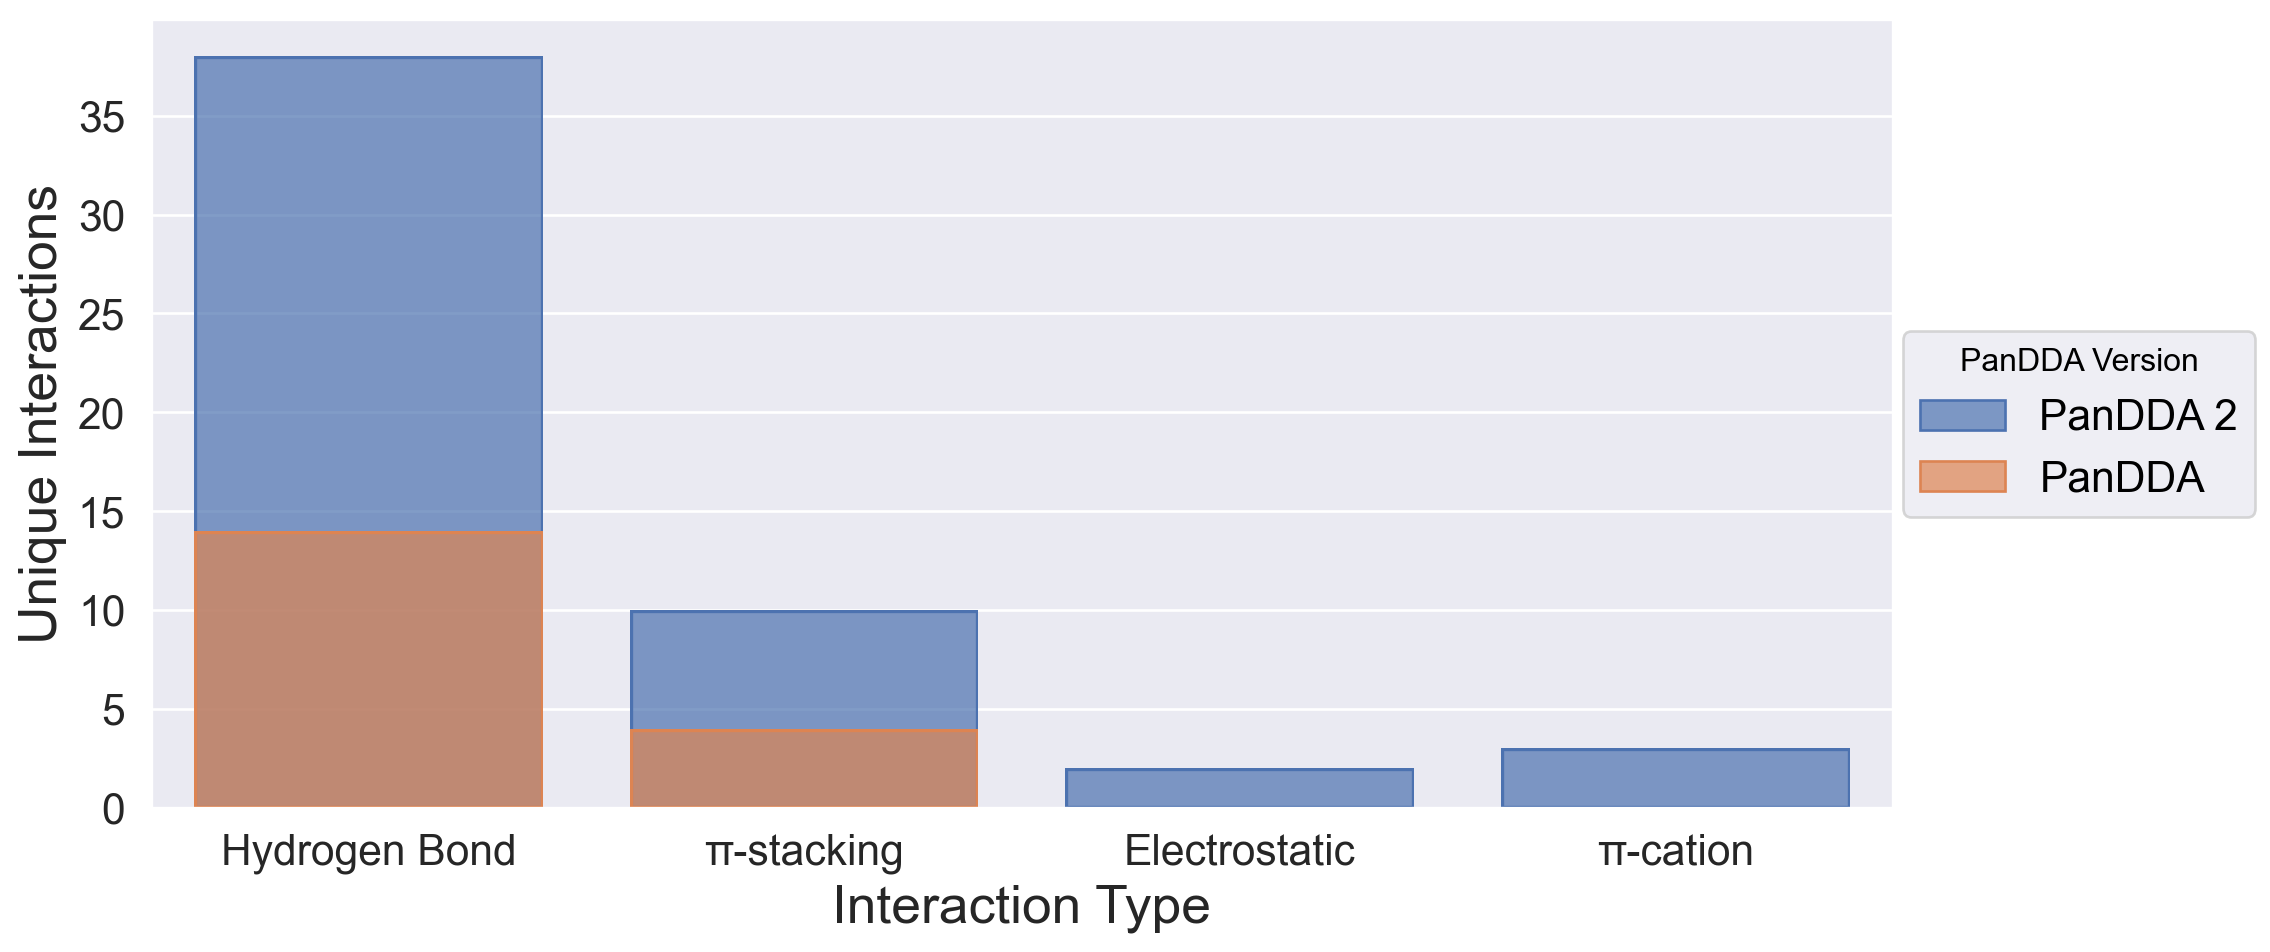

In [16]:
# fig, ax = plt.subplots()
# f = mpl.figure.Figure(figsize=(8, 4))
# sf1, sf2 = f.subfigures(1, 2)
plot = (
    so.Plot(data=plot_df, x="Interaction Type", y='Unique Interactions', color='PanDDA Version', text='Unique Interactions',)
    .add(so.Bar(), )
    # .add(so.Text(valign='bottom', halign='center', offset=10,  fontsize=20), )
    # .label(legend='PanDDA Version', fontsize=50)
    .layout(size=(10,5), )
    .theme({"font.size":8,"axes.labelsize":20, 'xtick.labelsize': 16, 'ytick.labelsize' : 16, 'legend.fontsize': 16})
)
# for container in sf1.axes[0].containers:
#     sf1.axes[0].bar_label(container)
plot.plot()

In [ ]:
sf2.axes

[]

In [ ]:
plot.config